# EEG Motor Imagery Classification

The goal of this project is to classify left-hand versus right-hand motor imagery using EEG signals.

**Research question:** Can machine learning distinguish between these two classes based on EEG-derived features?

**Workflow:** Data inspection → Signal processing → Feature extraction → Model training → Evaluation.

**Dataset:** [PhysioNet EEG Motor Movement/Imagery Dataset](https://physionet.org/content/eegmmidb/1.0.0/)

The initial experiment focuses on one participant and one recording.

In [17]:
import sys
from pathlib import Path

import mne
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version.split()[0])
print("MNE:", mne.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Python: 3.11.17
MNE: 1.13.2
NumPy: 2.4.6
Pandas: 3.0.6
SciPy: 1.17.1
Scikit-learn: 1.9.1


In [2]:
project_root = Path.cwd().parent

raw_data_dir = project_root / "data" / "raw"
processed_data_dir = project_root / "data" / "processed"
figures_dir = project_root / "reports" / "figures"

for directory in [raw_data_dir, processed_data_dir, figures_dir]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Raw data:", raw_data_dir)
print("Processed data:", processed_data_dir)
print("Figures:", figures_dir)

Project root: /Users/LOCAL_USER/PycharmProjects/EEG-Classification/eeg-ml-project
Raw data: /Users/LOCAL_USER/PycharmProjects/EEG-Classification/eeg-ml-project/data/raw
Processed data: /Users/LOCAL_USER/PycharmProjects/EEG-Classification/eeg-ml-project/data/processed
Figures: /Users/LOCAL_USER/PycharmProjects/EEG-Classification/eeg-ml-project/reports/figures


In [3]:
file_path = raw_data_dir / "S001R04.edf"

if not file_path.is_file() or file_path.stat().st_size == 0:
    raise FileNotFoundError("S001R04.edf is missing. ""Run: python scripts/download_data.py")

print("File:", file_path)
print("Size:", round(file_path.stat().st_size / 1024**2, 2), "MB")

File: /Users/LOCAL_USER/PycharmProjects/EEG-Classification/eeg-ml-project/data/raw/S001R04.edf
Size: 2.48 MB


## Data Loading

The EEG recording is stored in EDF format and is loaded using MNE-Python. Initial inspection focuses on the recording duration, sampling frequency, channel names, and basic metadata.

The recording `S001R04.edf` is loaded from the PhysioNet EEG Motor Movement/Imagery Dataset. The original file is preserved in `data/raw/`.

**Scope:** This exploratory analysis uses a single recording (`S001R04`) to understand the dataset structure and signal characteristics. Generalization across recordings and participants will be examined in later stages.

In [4]:
raw = mne.io.read_raw_edf(file_path, preload=False, verbose=False)

print("Number of channels:", len(raw.ch_names))
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Recording duration:", round(raw.n_times / raw.info["sfreq"], 2), "seconds")
print("First 10 channel names:", raw.ch_names[:10])

Number of channels: 64
Sampling frequency: 160.0 Hz
Recording duration: 125.0 seconds
First 10 channel names: ['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..']


### Channel Selection

Channels C3, Cz, and C4 are selected for initial exploration because they cover central sensorimotor regions associated with motor imagery.

This selection simplifies signal inspection. Later experiments may use a broader channel set to evaluate whether additional spatial information improves classification.

In [5]:
channels = ["C3..", "Cz..", "C4.."]

print("Selected channels:", channels)
print("Available channels:", [ch for ch in raw.ch_names if ch in channels])

Selected channels: ['C3..', 'Cz..', 'C4..']
Available channels: ['C3..', 'Cz..', 'C4..']


## Initial Data Inspection

The recording contains **64 EEG channels**, sampled at **160 Hz**, with a total duration of **125 seconds**.

The data array has shape `(64, 20000)`, representing channels and time samples.

MNE stores EEG amplitudes in volts by default.

## 2. Annotations and Events

The recording contains three event types:

- `T0` — Rest.
- `T1` — Left-fist motor imagery.
- `T2` — Right-fist motor imagery.

We inspect event timing, duration, and class distribution to understand how the continuous EEG signal is divided into labeled segments.

The classification task will focus on `T1` versus `T2`, excluding rest periods (`T0`).


In [6]:
annotations_df = pd.DataFrame({"onset_seconds": raw.annotations.onset,
                               "duration_seconds": raw.annotations.duration,
                               "label": raw.annotations.description})

print("Number of annotation segments:", len(annotations_df))
print("\nAnnotation counts:")
print(annotations_df["label"].value_counts().sort_index())

display(annotations_df.head())

Number of annotation segments: 30

Annotation counts:
label
T0    15
T1     8
T2     7
Name: count, dtype: int64


,onset_seconds,duration_seconds,label
0,0.0,4.2,T0
1,4.2,4.1,T2
2,8.3,4.2,T0
3,12.5,4.1,T1
4,16.6,4.2,T0


In [7]:
events, event_id = mne.events_from_annotations(raw, verbose=False)

print("Event IDs:", event_id)
print("\nFirst 15 events:")
print(events[:15])

event_labels = {value: key for key, value in event_id.items()}
event_counts = pd.Series(events[:, 2]).map(event_labels).value_counts().sort_index()

print("\nEvent counts:")
print(event_counts)

Event IDs: {'T0': 1, 'T1': 2, 'T2': 3}

First 15 events:
[[   0    0    1]
 [ 672    0    3]
 [1328    0    1]
 [2000    0    2]
 [2656    0    1]
 [3328    0    2]
 [3984    0    1]
 [4656    0    3]
 [5312    0    1]
 [5984    0    3]
 [6640    0    1]
 [7312    0    2]
 [7968    0    1]
 [8640    0    3]
 [9296    0    1]]

Event counts:
T0    15
T1     8
T2     7
Name: count, dtype: int64


### Observations

- The recording contains 30 annotated segments: 15 rest, 8 left-hand imagery, and 7 right-hand imagery.
- The two motor imagery classes are nearly balanced, but only 15 task segments are available in this recording.
- Event sample indices and labels were successfully extracted for subsequent epoch creation.

Additional recordings will be needed to obtain a larger dataset for model training and evaluation.

## 3. Time-Domain Visualization

The EEG signals from channels C3, Cz, and C4 are visualized in the time domain to inspect their amplitude variations and identify potential irregularities.

Visual inspection provides an initial overview of the signals but is not sufficient on its own to establish signal quality or identify all artifacts.

Using matplotlib as 2D backend.


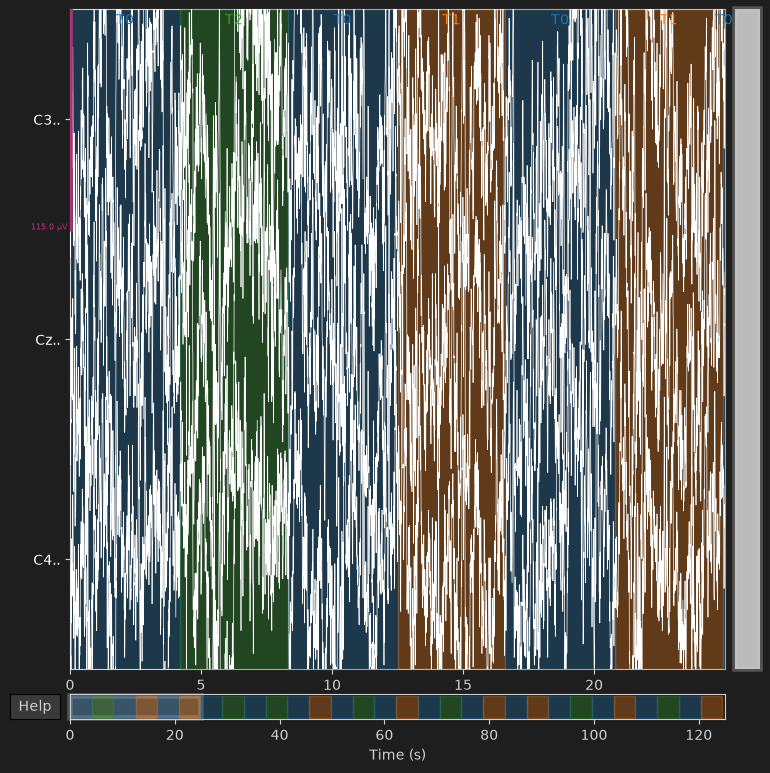

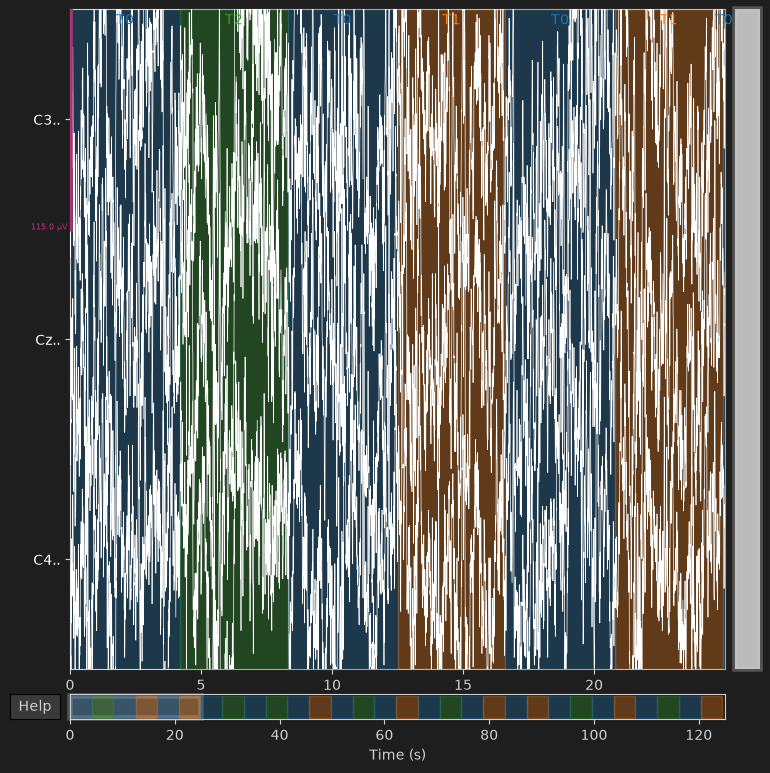

In [8]:
raw.plot(picks=channels, start=0, duration=25, scalings="auto")


The initial plot shows 25 seconds of EEG activity, making the signals difficult to inspect due to overlapping fluctuations.

To improve readability, we reduce the visualization window to 3 seconds. This allows us to examine the signal's short-term variations in greater detail.

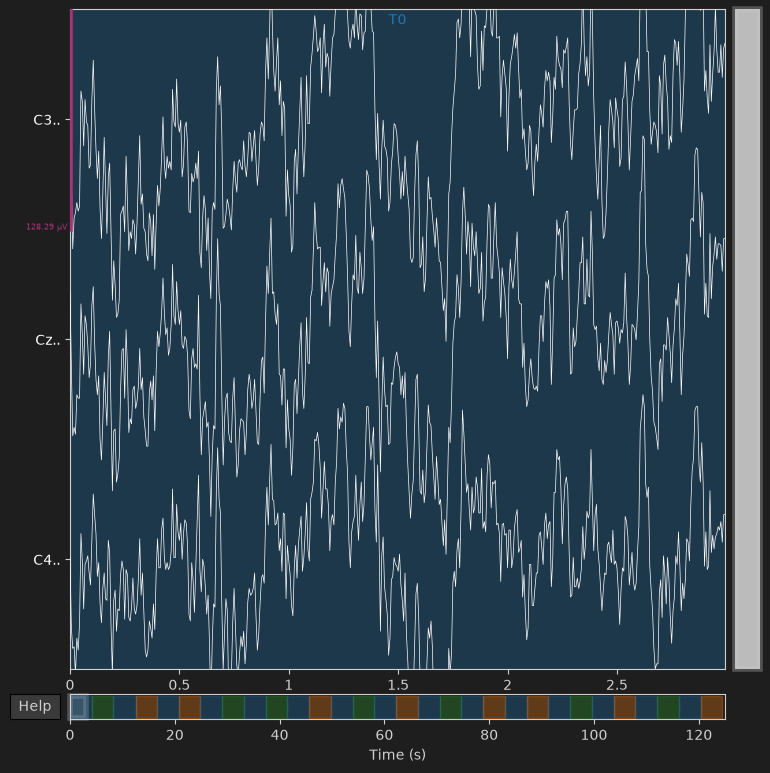

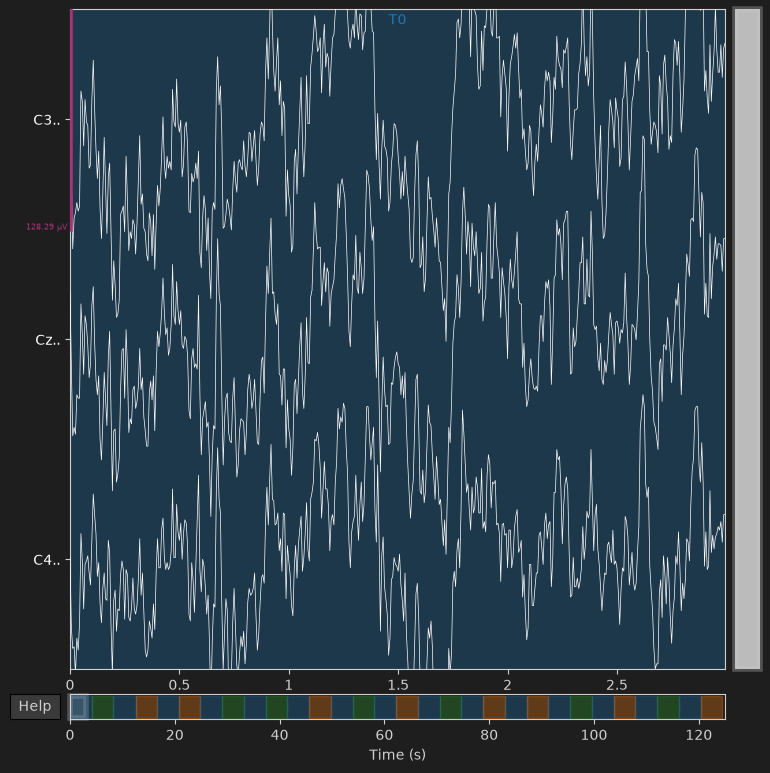

In [9]:
raw.plot(picks=channels,  start=0, duration=3, scalings="auto")

### Motor Imagery Segment Inspection

After inspecting the resting-state signal, we visualize a short segment during right-hand motor imagery (`T2`).

This allows us to inspect signal quality during the task, although class-specific motor imagery patterns may not be directly visible in raw EEG waveforms.

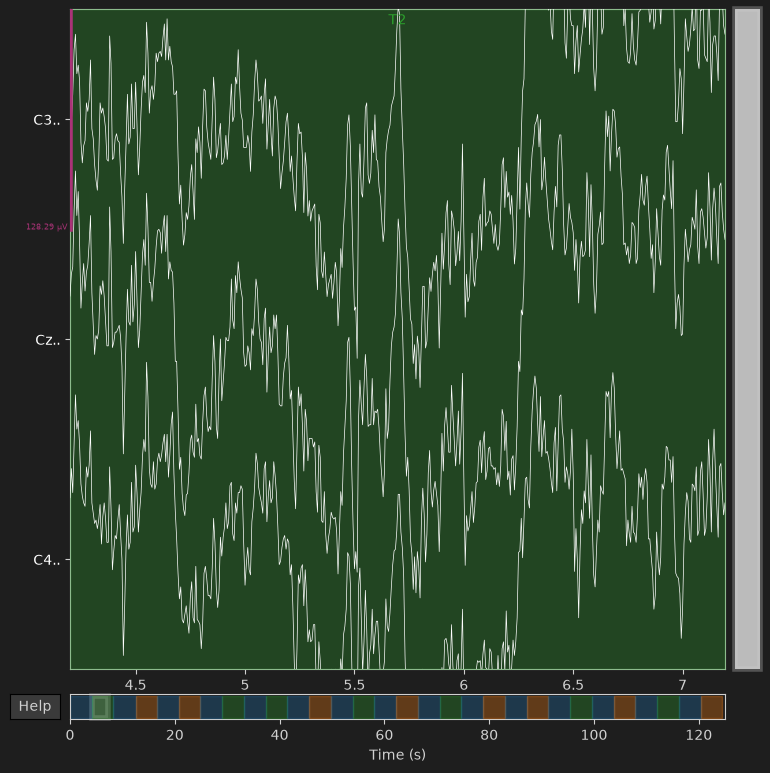

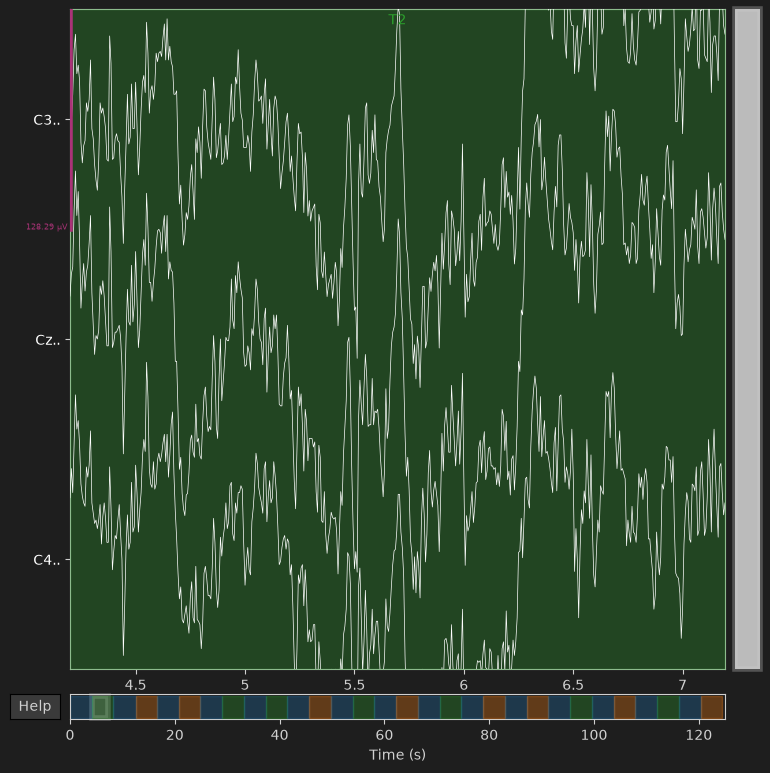

In [10]:
raw.plot(picks=channels, start=4.2, duration=3, scalings="auto")

## 4. Frequency-Domain Analysis

Power spectral density (PSD) describes how signal power is distributed across frequencies.

Welch's method estimates the PSD by averaging modified periodograms calculated from overlapping signal segments. We estimate the PSD for channels C3, Cz, and C4 in the 1–40 Hz range.

The frequency-bin spacing is determined by the sampling frequency and FFT length:

$$
\Delta f = \frac{f_s}{N_{\mathrm{FFT}}}
= \frac{160}{512}
= 0.3125\ \mathrm{Hz}
$$


The resulting PSD array contains three channels and 125 frequency bins. The spectrum represents the entire recording, including rest and both motor-imagery conditions. Therefore, it cannot yet reveal class-specific spectral differences.

In [11]:
spectrum = raw.compute_psd(method="welch", picks=channels, fmin=1, fmax=40, n_fft=512, verbose=False)
psd, freqs = spectrum.get_data(return_freqs=True)
print("PSD shape:", psd.shape)
print("Frequency range:", freqs[0], "-", freqs[-1], "Hz")
print("Frequency resolution:", round(freqs[1] - freqs[0], 3), "Hz")

PSD shape: (3, 125)
Frequency range: 1.25 - 40.0 Hz
Frequency resolution: 0.312 Hz


### Frequency Bands of Interest

We focus on two frequency bands commonly investigated in motor-related EEG research:

- **Mu/Alpha (8–13 Hz):** Includes sensorimotor mu activity and overlaps with the conventional alpha band.
- **Beta (13–30 Hz):** Associated with sensorimotor rhythms and commonly studied in motor control research.

These bands are initial candidates for feature extraction. Their discriminative value for left- versus right-hand motor imagery must be evaluated using condition-specific data.

Note that the two bands share the boundary at 13 Hz in this convention; the discrete PSD frequency bins do not necessarily fall exactly on the band boundaries.

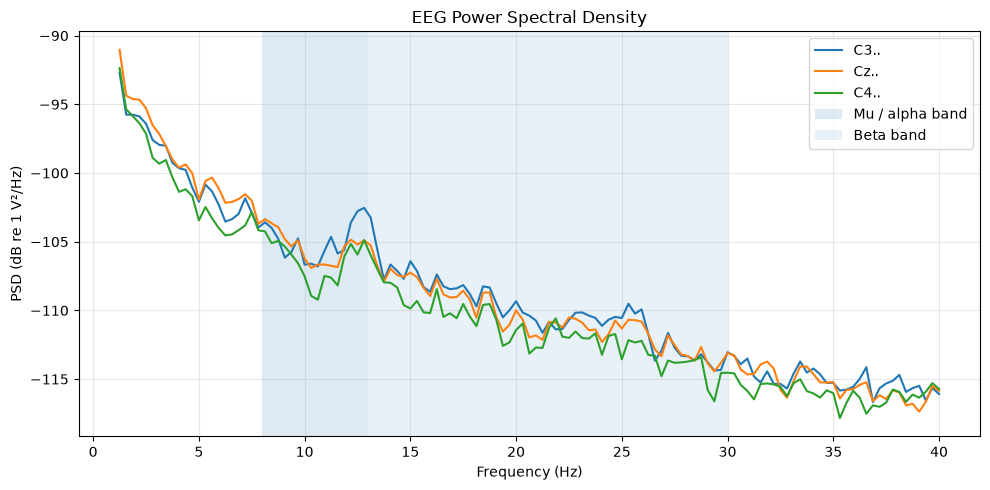

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

for i, channel in enumerate(channels):
    psd_db = 10 * np.log10(psd[i])
    ax.plot(freqs, psd_db, label=channel)

ax.axvspan(8, 13, alpha=0.15, label="Mu / alpha band")
ax.axvspan(13, 30, alpha=0.10, label="Beta band")

ax.set_title("EEG Power Spectral Density")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (dB re 1 V²/Hz)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observations

- PSD shows a broadly decreasing trend with frequency, consistent with a typical EEG spectral pattern.
- A local peak around 12–13 Hz is most prominent in C3.
- C3, Cz, and C4 show similar spectral shapes with differences in power magnitude.

**Limitation:** The PSD represents the entire recording, combining rest and both motor imagery conditions. Therefore, class-specific differences cannot yet be identified.

**Next step:** Quantify Mu/Alpha and Beta band power to summarize the spectral characteristics of each channel.

## 5. Absolute and Relative Band Power

Band power quantifies the spectral power contained within a specified frequency range.

- **Absolute band power:** The integral of the PSD over a frequency band, expressed in V².
- **Relative band power:** The percentage of total analyzed spectral power contained within that band.

Relative power is calculated with respect to the total PSD power across the analyzed frequency range, approximately 1.25–40 Hz.

The analysis is performed for channels C3, Cz, and C4 using the Mu/Alpha (8–13 Hz) and Beta (13–30 Hz) bands. Because the PSD is calculated over the entire recording, these results describe overall spectral characteristics rather than differences between task conditions.


1. Absolute band power — total spectral power within a frequency band.
$$
P_{\text{band}} = \int_{f_{\min}}^{f_{\max}} PSD(f),df
$$
2. Relative band power — proportion of total spectral power within the band.
$$
P_{\text{relative}} = \frac{P_{\text{band}}}{P_{\text{total}}}
$$


In [13]:
bands = {"Mu/alpha (8-13 Hz)": (8, 13),
         "Beta (13-30 Hz)": (13, 30)}

total_power = np.trapezoid(psd, freqs, axis=1)
results = []

for i, channel in enumerate(channels):
    for band_name, (fmin, fmax) in bands.items():
        interior_mask = (freqs > fmin) & (freqs < fmax)
        band_freqs = np.concatenate(([fmin], freqs[interior_mask], [fmax]))
        band_psd = np.interp(band_freqs, freqs, psd[i])

        absolute_power = np.trapezoid(band_psd, band_freqs)
        relative_power = absolute_power / total_power[i] * 100

        results.append({
            "Channel": channel.removesuffix(".."),
            "Band": band_name,
            "Absolute power (V²)": absolute_power,
            "Relative power (%)": relative_power})

band_power_df = pd.DataFrame(results)

display(band_power_df.style.format({
    "Absolute power (V²)": "{:.3e}",
    "Relative power (%)": "{:.2f}"}))

,Channel,Band,Absolute power (V²),Relative power (%)
0,C3,Mu/alpha (8-13 Hz),1.662e-10,13.23
1,C3,Beta (13-30 Hz),1.929e-10,15.36
2,Cz,Mu/alpha (8-13 Hz),1.487e-10,10.41
3,Cz,Beta (13-30 Hz),1.693e-10,11.86
4,C4,Mu/alpha (8-13 Hz),1.192e-10,11.67
5,C4,Beta (13-30 Hz),1.339e-10,13.11


### Observations

- C3 shows the highest absolute and relative power in both Mu/Alpha and Beta bands.
- Integrated Beta power exceeds Mu/Alpha power across all three channels, partly reflecting the wider Beta frequency range.
- Mu/Alpha and Beta together account for approximately 22–29% of the total analyzed spectral power, depending on the channel.

**Limitation:** These values represent the entire recording, including rest and both motor imagery conditions. They do not yet indicate how well the features distinguish T1 from T2.

**Next step:** Identify dominant spectral peaks within the Mu/Alpha range.


## 6. Peak Detection

We detect local PSD maxima within the 8–16 Hz range and select the peak with the highest PSD value within the Mu/Alpha band (8–13 Hz).

For each selected peak, we calculate its frequency, PSD value, and prominence to describe its local spectral characteristics.

In [14]:
from scipy.signal import find_peaks, peak_prominences

results = []

for i, channel in enumerate(channels):
    broader_mask = (freqs >= 8) & (freqs <= 16)
    broader_freqs = freqs[broader_mask]
    broader_psd = psd[i, broader_mask]

    peaks, _ = find_peaks(broader_psd)

    mu_peak_mask = ((broader_freqs[peaks] >= 8) & (broader_freqs[peaks] <= 13))
    mu_peaks = peaks[mu_peak_mask]

    if len(mu_peaks) > 0:
        prominences = peak_prominences(broader_psd, peaks)[0]
        selected_peak = mu_peaks[
            np.argmax(broader_psd[mu_peaks])]
        prominence_idx = np.where(peaks == selected_peak)[0][0]

        peak_freq = broader_freqs[selected_peak]
        peak_power = broader_psd[selected_peak]
        prominence = prominences[prominence_idx]
    else:
        peak_freq = np.nan
        peak_power = np.nan
        prominence = np.nan

    results.append({"Channel": channel.removesuffix(".."),
                    "Peak frequency (Hz)": peak_freq,
                    "Peak PSD (V²/Hz)": peak_power,
                    "Peak prominence (V²/Hz)": prominence})

peak_df = pd.DataFrame(results)

display(peak_df.style.format({"Peak frequency (Hz)": "{:.3f}",
                              "Peak PSD (V²/Hz)": "{:.3e}",
                              "Peak prominence (V²/Hz)": "{:.3e}"}))

,Channel,Peak frequency (Hz),Peak PSD (V²/Hz),Peak prominence (V²/Hz)
0,C3,12.812,5.577e-11,3.485e-11
1,Cz,12.188,3.274e-11,1.238e-11
2,C4,12.812,3.249e-11,2.053e-11


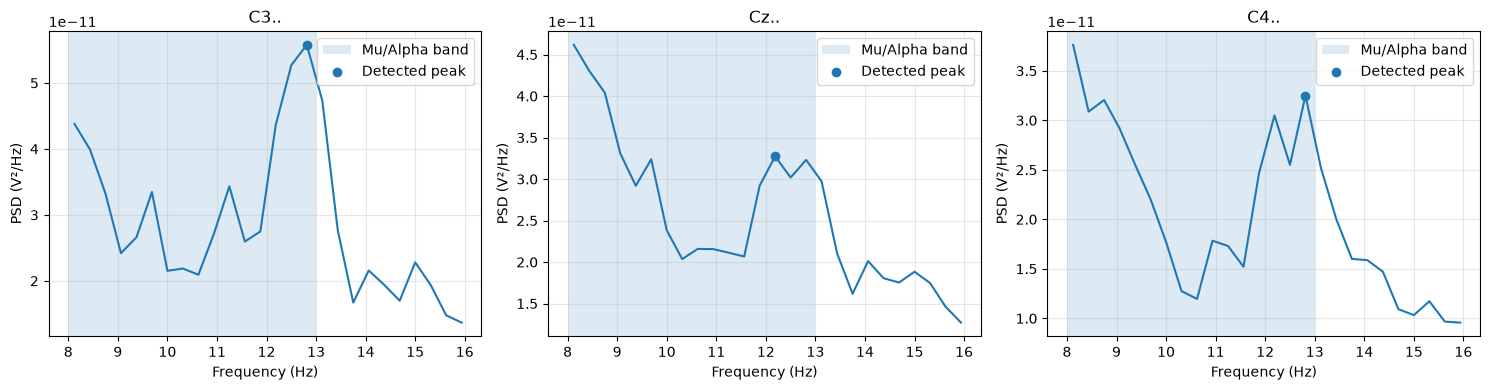

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, channel in enumerate(channels):
    mask = (freqs >= 8) & (freqs <= 16)

    axes[i].plot(freqs[mask], psd[i, mask])
    axes[i].axvspan(8, 13, alpha=0.15, label="Mu/Alpha band")

    peak_freq = peak_df.loc[i, "Peak frequency (Hz)"]
    peak_power = peak_df.loc[i, "Peak PSD (V²/Hz)"]

    if pd.notna(peak_freq):
        axes[i].scatter(peak_freq, peak_power, zorder=3, label="Detected peak")

    axes[i].set_title(channel)
    axes[i].set_xlabel("Frequency (Hz)")
    axes[i].set_ylabel("PSD (V²/Hz)")
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Observations

- Local spectral peaks occur near 12–13 Hz across C3, Cz, and C4.
- C3 shows the highest peak PSD and prominence.
- Peak characteristics describe the overall recording and cannot yet be attributed to specific motor imagery conditions.

**Next step:** Preprocess the EEG signal and extract event-specific epochs to investigate differences between T1 and T2.

## 7. Exploration Summary

We consolidate the recording metadata, event counts, band power measurements, and detected spectral peaks to summarize the initial exploratory analysis.

In [16]:
print("Recording duration:", round(raw.n_times / raw.info["sfreq"], 2), "s")
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Selected channels:", channels)
print("PSD shape:", psd.shape)
print("Event counts:")
print(event_counts)
print("\nBand power features:")
display(band_power_df)
print("\nDetected peaks:")
display(peak_df)

Recording duration: 125.0 s
Sampling frequency: 160.0 Hz
Selected channels: ['C3..', 'Cz..', 'C4..']
PSD shape: (3, 125)
Event counts:
T0    15
T1     8
T2     7
Name: count, dtype: int64

Band power features:


,Channel,Band,Absolute power (V²),Relative power (%)
0,C3,Mu/alpha (8-13 Hz),1.662302e-10,13.233043
1,C3,Beta (13-30 Hz),1.928914e-10,15.355457
2,Cz,Mu/alpha (8-13 Hz),1.486679e-10,10.413522
3,Cz,Beta (13-30 Hz),1.692598e-10,11.855891
4,C4,Mu/alpha (8-13 Hz),1.191869e-10,11.670338
5,C4,Beta (13-30 Hz),1.338922e-10,13.110219



Detected peaks:


,Channel,Peak frequency (Hz),Peak PSD (V²/Hz),Peak prominence (V²/Hz)
0,C3,12.8125,5.576933e-11,3.484756e-11
1,Cz,12.1875,3.274458e-11,1.238200e-11
2,C4,12.8125,3.249307e-11,2.052946e-11


## Summary and Limitations

### Key Findings

- The recording contains 64 EEG channels sampled at 160 Hz, with 30 annotated events (15 rest, 8 left-hand imagery, 7 right-hand imagery).
- C3 shows the highest Mu/Alpha and Beta band power among the three selected channels.
- Spectral peaks occur near 12–13 Hz across C3, Cz, and C4.

### Limitations

- The analysis is based on a single recording (`S001R04`).
- PSD and band power were calculated over the entire recording, combining rest and both motor imagery conditions.
- The observed spectral characteristics do not yet demonstrate differences between T1 and T2.

### Next Steps

Preprocess the EEG signal, extract event-specific epochs, and calculate features separately for each motor imagery trial.

The processing pipeline will subsequently be extended to additional recordings and participants to evaluate model generalization.